# End-to-end LPBBTI Financial Position Analysis

## 0. Project Overview

### 0.1. Project Scope
Monthly financial position of LPBBTI providers in Indonesia (OJK Table 2, 2021–2025). 

The main analysis uses 2022–2025 and 2021 is background only. 

Account-level analysis is split into two reporting-structure segments: 2022–2023 and 2024–2025.

**Terms:**
- **Category:** Assets, Liabilities, or Equity.
- **Total:** the "Total …" row of a category, such as Total Assets.
- **Classification:** a group within Assets (Current, Fixed) or Liabilities (Current, Long-Term). Equity has none.
- **Subtotal:** the "Total …" row of a classification, such as Total Current Assets. Total Equity also counts as a subtotal.
- **Account:** the lowest-level row, such as Cash and Cash Equivalents.
- **Parent / Child:** a parent groups child rows (Affiliated Party, Third Party), written "Parent - Child", such as Other Current Receivables - Affiliated Party.

### 0.2. Research Questions
- How did the overall financial position of LPBBTI providers change over time, by total assets, total liabilities, and total equity?
- Which accounts changed the most within comparable reporting periods, and how did those changes contribute to the related subtotal?
- Which accounts show sustained or unusual monthly movements, and how can we tell a lasting change from a temporary one?

| | Analysis | Findings |
|---|---|---|
| RQ 1 | 11.3 | 12.1 |
| RQ 2 | 11.4 | 12.2 |
| RQ 3 | 11.5 | 12.3 |
| Non RQ | 11.1, 11.2 | 12.4 |

Non RQ sections support the RQs and do not answer them.

### 0.3. Analytical Approach
The analysis is descriptive. It shows what changed and when, not why. Read the results with the limits in Section 0.4 in mind.

### 0.4. Analytical Scope
- **Periods:** 2021 starts in May (Jan–Apr are unavailable). Account-level checks run separately for 2022–2023 and 2024–2025. RQ 2 also compares 2023–2024, which is exploratory.
- **Report format change in 2024:** Dec-23 values are the same in both reports, but the 2024 report adds eight rows (Section 8.3), and seven new accounts only have values from Jul-24 (Section 11.1). This follows OJK Circular Letter No. 1/SEOJK.06/2024, effective 1 July 2024 ([source](https://ojk.go.id/id/regulasi/Documents/Pages/Tata-Cara-dan-Mekanisme-Penyampaian-Data-Transaksi-Pendanaan-dan-Pelaporan-Penyelenggara-Layanan-Pendanaan-Bersama-Berbasis/SEOJK%201-SEOJK.06-2024%20Tata%20Cara%20dan%20Mekanisme%20Penyampaian%20Data%20Transaksi%20Pendanaan%20dan%20Pelaporan%20Penyelenggara%20LPBBTI.pdf)). These new accounts are analyzed only in 2024-2025.
- **Fixes:** two problems in the 2024 report were fixed for the analysis, Financial Debt in Sep-24 and the unallocated receivables in Jul-Aug 2024 (Section 9.1). The original values are kept.
- **Reading the results:** values are monthly balances in billion Rupiah. A flagged (unusual) month is something to check, not a confirmed error. A flagged change is lasting if the balance 3 months later is closer to the new balance than to the old one, and temporary otherwise (Section 11.5.3).

## 1. Data Ingestion

### 1.1. Imports & Configuration


In [112]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from IPython.display import display

In [113]:
RAW_DIR = Path('../data/raw')
CLEAN_DIR = Path('../data/clean/Statistik LPBBTI 2022-2025.xlsx')
FIGURE_DIR = Path('../figures')

YEARS = range(2021, 2026)
MAIN_YEARS = range(2022, 2026)

SHEET_NAME = '2'
HEADER = 1

### 1.2. Load Data





In [114]:
reports = {year: pd.read_excel(RAW_DIR/f'STATISTIK LPBBTI Desember {year}.xlsx', sheet_name=SHEET_NAME, header=HEADER) for year in YEARS}

## 2. Data Inspection


### 2.1. Dataset Inspection


In [115]:
for year, df in reports.items():
  print(f'''{year}:
Shape: {df.shape}
Columns: {df.columns.tolist()}
10 Accounts:{df.iloc[:10,0].tolist()}\n''')

2021:
Shape: (30, 13)
Columns: ['Akun / Account', datetime.datetime(2021, 1, 1, 0, 0), datetime.datetime(2021, 2, 1, 0, 0), datetime.datetime(2021, 3, 1, 0, 0), datetime.datetime(2021, 4, 1, 0, 0), datetime.datetime(2021, 5, 1, 0, 0), datetime.datetime(2021, 6, 1, 0, 0), datetime.datetime(2021, 7, 1, 0, 0), datetime.datetime(2021, 8, 1, 0, 0), datetime.datetime(2021, 9, 1, 0, 0), datetime.datetime(2021, 10, 1, 0, 0), datetime.datetime(2021, 11, 1, 0, 0), datetime.datetime(2021, 12, 1, 0, 0)]
10 Accounts:['Aset / Assets', 'Kas dan Setara Kas / Cash and Cash equivalents', 'Piutang Lainnya / Other Receivables', 'Pajak dibayar di muka / Prepaid Taxes', 'Biaya dibayar di muka / Prepaid Expenses', 'Investasi Lainnya / Other Investments', 'Aset Pajak yang ditangguhkan / Deferred Taxes', 'Aset tidak Berwujud / Intangible Assets', 'Gedung, Tanah dan Peralatan / Building, Land and Equipment', 'Aset lain-lain / Other Assets']

2022:
Shape: (54, 14)
Columns: ['Akun', datetime.datetime(2022, 1, 22,

### 2.2. Inspect Period Columns

In [116]:
label_columns = ['Akun / Account', 'Akun', 'Account']
period_summary = []

for year, df in reports.items():
  period_cols = df.columns.drop(label_columns,  errors='ignore')
  periods = pd.DatetimeIndex(period_cols)
  period_summary.append({'Year': year, 'Number of Period Columns': len(periods), 'First Period': periods.min(), 'Last Period': periods.max()})

pd.DataFrame(period_summary)

,Year,Number of Period Columns,First Period,Last Period
0,2021,12,2021-01-01,2021-12-01
1,2022,12,2022-01-22,2022-12-22
2,2023,21,2022-01-22,2023-12-01
3,2024,13,2023-12-01,2024-12-01
4,2025,13,2024-12-01,2025-12-01


### 2.3. Identify Source Notes
- The 2021 file has one account column with the Indonesian and English names together. The 2022-2025 files have separate columns.
- The files overlap: the 2023 file repeats Jan-Aug and Dec 2022, the 2024 file starts at Dec-23 and the 2025 file at Dec-24.

## 3. Dataframe Schema & Account Standardization

### 3.1. Standardize Dataframe Structure & Account Labels

In [117]:
for year, df in reports.items():
  if year == 2021:
    df = df.rename(columns={df.columns[0]: 'Account'})
    df['Account'] = df['Account'].str.split('/').str[-1].str.strip().str.replace(r'\s+', ' ', regex=True)

  else:
    df = df.drop(columns='Akun')
    df.insert(0, 'Account', df.pop('Account'))
    df['Account'] = df['Account'].str.strip().str.replace(r'\s+', ' ', regex=True)

  df['Account'] = df['Account'].replace({'Total Liablities and Equities': 'Total Liabilities and Equities', 'Total Equities': 'Total Equity', 'Equities': 'Equity',
                                         'Bulding, Land and Equipment': 'Building, Land and Equipment', 'Deffered Tax Assets': 'Deferred Tax Assets',})

  df['Account'] = (df['Account'].str.title().str.replace(r'\bAnd\b', 'and', regex=True).str.replace(r'\bFor\b', 'for', regex=True).
                   str.replace(r'\bOf\b', 'of', regex=True).str.replace(r'\bThe\b', 'the', regex=True).str.replace('Long Term', 'Long-Term', regex=False).
                   str.replace('Short Term', 'Short-Term', regex=False))

  reports[year] = df

reports[2025].head()

,Account,2024-12-01 00:00:00,2025-01-01 00:00:00,2025-02-01 00:00:00,2025-03-01 00:00:00,2025-04-01 00:00:00,2025-05-01 00:00:00,2025-06-01 00:00:00,2025-07-01 00:00:00,2025-08-01 00:00:00,2025-09-01 00:00:00,2025-10-01 00:00:00,2025-11-01 00:00:00,2025-12-01 00:00:00
0,Assets,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,Current Assets,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,Cash and Cash Equivalents,3909.517228,4178.798486,4538.734638,4311.797442,4513.538868,4818.611293,4967.967069,4551.694036,4629.064556,4232.292706,4605.163594,4973.079303,5089.675933
3,Accounts Receivables,1381.175692,1429.847852,1414.047808,1386.564740,1400.968226,1424.857137,1541.951588,1641.638866,1803.056255,1920.182607,1965.972527,2030.987125,2039.732152
4,Affiliated Party,51.080779,52.663191,55.541380,53.687384,53.140748,50.406804,9.129263,8.432248,8.572315,21.235518,6.711304,24.810865,34.063456


### 3.2. Account Label Audit

#### 3.2.1. Unique Names

In [118]:
sorted(set(pd.concat([df['Account'] for df in reports.values()]).dropna()))

['*Data Tersedia Mulai Periode Bulan Mei 2021',
 'Account Payable - Third Party',
 'Accounts Payable',
 'Accounts Receivables',
 'Accrued Expenses',
 'Accumulated Amortization',
 'Accumulated Depreciation',
 'Additional Paid-Up Capital',
 'Affiliated Party',
 'Allowance for Impairment Losses',
 'Assets',
 'Building, Land and Equipment',
 'Capital Deposit Down Payment',
 'Cash and Cash Equivalents',
 'Current Assets',
 'Current Liabilities',
 'Deferred Tax Assets',
 'Deferred Tax Liabilities',
 'Deferred Taxes',
 'Equity',
 'Financial Debt',
 'Fixed Assets',
 'Intangible Assets',
 'Lease Liabilities',
 'Liabilities',
 'Long-Term Investments',
 'Long-Term Liabilities',
 'Non-Controlling Interests',
 'Other Assets',
 'Other Current Assets',
 'Other Current Liabilities',
 'Other Current Receivables',
 'Other Equity',
 'Other Fixed Assets',
 'Other Investments',
 'Other Liabilities',
 'Other Long-Term Liabilities',
 'Other Long-Term Receivables',
 'Other Payables',
 'Other Receivables',
 'P

#### 3.2.2. Repeated Names per Year

In [119]:
name_counts = pd.DataFrame([{'Year': year, 'Account': account, 'Count': count}
              for year, df in reports.items()
              for account, count in df['Account'].value_counts().items()])

name_counts[name_counts['Count'] > 1]

,Year,Account,Count
28,2022,Third Party,4
29,2022,Affiliated Party,4
73,2023,Third Party,4
74,2023,Affiliated Party,4
118,2024,Affiliated Party,5
119,2024,Third Party,5
169,2025,Affiliated Party,5
170,2025,Third Party,5


#### 3.2.3. Unique Names & Rows per Year

In [120]:
pd.DataFrame([{'Year': year, 'Unique Names': df['Account'].nunique(), 'Rows': len(df)} for year, df in reports.items()])

,Year,Unique Names,Rows
0,2021,28,30
1,2022,45,54
2,2023,45,51
3,2024,51,61
4,2025,51,61


## 4. Structural Row Identification

### 4.1. Identify Blank & Footnote Rows

In [121]:
blank_footnote_rows = []
footnote_names = []

for year, df in reports.items():
  account = df['Account']
  account_masks = [(account.isna(), 'Blank Account'), (account.str.startswith('*', na=False), 'Footnote Account')]
  
  is_footnote = df['Account'].str.startswith('*', na=False)
  footnote_names.extend(df.loc[is_footnote, 'Account'].dropna().tolist())

  for mask, account_type in account_masks:
    blank_footnote_rows.extend([{'Year': year, 'Index': idx, 'Account Type': account_type, 'Account': df.at[idx, 'Account']} for idx in df.index[mask]])

footnote_names = list(dict.fromkeys(footnote_names))

blank_footnote_rows_table = pd.DataFrame(blank_footnote_rows).sort_values(by=['Year', 'Index']).reset_index(drop=True)
display(blank_footnote_rows_table, blank_footnote_rows_table.groupby(['Year', 'Account Type']).size().rename('Total Rows').reset_index())

,Year,Index,Account Type,Account
0,2021,27,Blank Account,NaN
1,2021,28,Blank Account,NaN
2,2021,29,Footnote Account,*Data Tersedia Mulai Periode Bulan Mei 2021
3,2022,51,Blank Account,NaN
4,2022,52,Blank Account,NaN
5,2022,53,Blank Account,NaN
6,2024,59,Blank Account,NaN
7,2024,60,Blank Account,NaN
8,2025,59,Blank Account,NaN
9,2025,60,Blank Account,NaN


,Year,Account Type,Total Rows
0,2021,Blank Account,2
1,2021,Footnote Account,1
2,2022,Blank Account,3
3,2024,Blank Account,2
4,2025,Blank Account,2


### 4.2. Identify Category & Classification Rows

In [122]:
cat_class_names = ['Assets', 'Current Assets', 'Fixed Assets', 'Liabilities', 'Current Liabilities', 'Long-Term Liabilities', 'Equity']

In [123]:
cat_class_rows = []

for year, df in reports.items():
  is_cat_class = df['Account'].isin(cat_class_names)

  cat_class_rows.extend([{'Year': year, 'Index': idx, 'Account': df.at[idx, 'Account']} for idx in df.index[is_cat_class]])

cat_class_rows_table = pd.DataFrame(cat_class_rows).sort_values(by=['Year', 'Index']).reset_index(drop=True)

display(cat_class_rows_table, cat_class_rows_table.groupby('Year').size().rename('Total Rows').reset_index())

,Year,Index,Account
0,2021,0,Assets
1,2021,11,Liabilities
2,2021,20,Equity
3,2022,0,Assets
4,2022,1,Current Assets
5,2022,11,Fixed Assets
6,2022,24,Liabilities
7,2022,25,Current Liabilities
8,2022,36,Long-Term Liabilities
9,2022,43,Equity


,Year,Total Rows
0,2021,3
1,2022,7
2,2023,7
3,2024,7
4,2025,7


### 4.3. Identify Total & Subtotal Rows

In [124]:
total_names = ['Total Assets', 'Total Liabilities', 'Total Equity']
subtotal_names = ['Total Current Assets', 'Total Fixed Assets', 'Total Current Liabilities', 'Total Long-Term Liabilities', 'Total Equity']
all_total_names = total_names + subtotal_names + ['Total Liabilities and Equities']

total_rows = []

for year, df in reports.items():
  is_total = df['Account'].isin(all_total_names)

  total_rows.extend([{'Year': year, 'Index': idx, 'Account': df.at[idx, 'Account']} for idx in df.index[is_total]])

total_rows_table = pd.DataFrame(total_rows).sort_values(['Year', 'Index']).reset_index(drop=True)

display(total_rows_table, total_rows_table.groupby('Year').size().rename('Total Rows').reset_index())

,Year,Index,Account
0,2021,10,Total Assets
1,2021,19,Total Liabilities
2,2021,25,Total Equity
3,2021,26,Total Liabilities and Equities
4,2022,10,Total Current Assets
5,2022,22,Total Fixed Assets
6,2022,23,Total Assets
7,2022,35,Total Current Liabilities
8,2022,41,Total Long-Term Liabilities
9,2022,42,Total Liabilities


,Year,Total Rows
0,2021,4
1,2022,8
2,2023,8
3,2024,8
4,2025,8


## 5. Account Hierarchy

### 5.1. Identify Parent & Child Relationships then Create Child Identifier

In [125]:
child_names = ['Affiliated Party', 'Third Party']
parent_child_rows = []

for year, df in reports.items():
  is_child = df['Account'].isin(child_names)
  parent = df['Account'].mask(is_child).ffill()

  parent_child_rows.append(pd.DataFrame({'Year': year, 'Index': df.index[is_child], 'Parent': parent[is_child], 'Child': df.loc[is_child, 'Account']}))
  df.loc[is_child, 'Account'] = (parent.loc[is_child] + ' - ' + df.loc[is_child, 'Account'])

parent_child_rows = pd.concat(parent_child_rows)
parent_names = parent_child_rows['Parent'].unique().tolist()
parent_child_rows['Account'] = (parent_child_rows['Parent'] + ' - ' + parent_child_rows['Child'])

parent_child_rows.head()

,Year,Index,Parent,Child,Account
7,2022,7,Other Current Receivables,Affiliated Party,Other Current Receivables - Affiliated Party
8,2022,8,Other Current Receivables,Third Party,Other Current Receivables - Third Party
19,2022,19,Other Long-Term Receivables,Affiliated Party,Other Long-Term Receivables - Affiliated Party
20,2022,20,Other Long-Term Receivables,Third Party,Other Long-Term Receivables - Third Party
29,2022,29,Other Current Liabilities,Affiliated Party,Other Current Liabilities - Affiliated Party


## 6. Cross Report Reconciliation

### 6.1. Identify Overlapping Periods

In [126]:
overlaps = {}

for y1, y2 in zip(YEARS, YEARS[1:]):
  period_cols_1 = reports[y1].columns.drop('Account')
  period_cols_2 = reports[y2].columns.drop('Account')
  shared_periods = period_cols_1.intersection(period_cols_2)

  if len(shared_periods) > 0:
    overlaps[(y1, y2)] = list(shared_periods)

pd.DataFrame([{'Report 1': y1, 'Report 2': y2, 'Overlapping Periods': [str(period) for period in periods]}
              for(y1, y2), periods in overlaps.items()])

,Report 1,Report 2,Overlapping Periods
0,2022,2023,"[2022-01-22 00:00:00, 2022-02-22 00:00:00, 202..."
1,2023,2024,[2023-12-01 00:00:00]
2,2024,2025,[2024-12-01 00:00:00]


### 6.2. Overlapping Periods Reconciliation

In [127]:
reconciliation = []

for (y1, y2), periods in overlaps.items():
  report_1 = reports[y1]
  report_2 = reports[y2]

  report_1 = report_1[report_1['Account'].notna()].set_index('Account')
  report_2 = report_2[report_2['Account'].notna()].set_index('Account')

  shared_names = report_1.index.intersection(report_2.index)
  values_1 = report_1.loc[shared_names, periods].astype(float)
  values_2 = report_2.loc[shared_names, periods].astype(float)

  compared = values_1.notna() & values_2.notna()
  matching = compared & np.isclose(values_1, values_2, rtol=1e-9, atol=1e-6)

  reconciliation.append({'Report 1': y1, 'Report 2': y2, 'Periods': len(periods), 'Only in Report 1': sorted(set(report_1.index) - set(report_2.index)), 'Only in Report 2': sorted(set(report_2.index) - set(report_1.index)),
                         'Compared Values': int(compared.sum().sum()), 'Matching Values': int(matching.sum().sum()), 'Missing in One Report': int((values_1.isna() ^ values_2.isna()).sum().sum())})

pd.DataFrame(reconciliation)

,Report 1,Report 2,Periods,Only in Report 1,Only in Report 2,Compared Values,Matching Values,Missing in One Report
0,2022,2023,9,[],[],396,396,0
1,2023,2024,1,[],"[Accounts Receivables, Accounts Receivables - ...",44,44,0
2,2024,2025,1,[],[],54,54,3


## 7. Data Quality

### 7.1. Missing Values

In [128]:
excluded_names = cat_class_names + all_total_names + footnote_names

In [129]:
missing_rows = []

for year, df in reports.items():
  df = df[df['Account'].notna() & ~df['Account'].isin(excluded_names)]
  period_cols = df.columns.drop('Account')

  missing = df[period_cols].isna()
  all_missing = missing.all(axis=1)
  partial_missing = missing.any(axis=1) & ~all_missing

  account_masks = [(all_missing, 'All Missing'), (partial_missing, 'Partial Missing')]

  for mask, account_type in account_masks:
    missing_rows.extend([{'Year': year, 'Index': idx, 'Row Type': account_type, 'Account': df.at[idx, 'Account']} for idx in df.index[mask]])

missing_rows_table = pd.DataFrame(missing_rows).sort_values(['Year', 'Index']).reset_index(drop=True)

display(missing_rows_table, missing_rows_table.groupby(['Year', 'Row Type']).size().rename('Total Rows').reset_index())

,Year,Index,Row Type,Account
0,2021,1,Partial Missing,Cash and Cash Equivalents
1,2021,2,Partial Missing,Other Receivables
2,2021,3,Partial Missing,Prepaid Taxes
3,2021,4,Partial Missing,Prepaid Expenses
4,2021,5,Partial Missing,Other Investments
5,2021,6,Partial Missing,Deferred Taxes
6,2021,7,Partial Missing,Intangible Assets
7,2021,8,Partial Missing,"Building, Land and Equipment"
8,2021,9,Partial Missing,Other Assets
9,2021,12,Partial Missing,Accounts Payable


,Year,Row Type,Total Rows
0,2021,Partial Missing,20
1,2024,Partial Missing,10


  ### 7.2. Identical Period Rows

In [130]:
identical_period_rows = []

for year, df in reports.items():
  df = df[df['Account'].notna() & ~df['Account'].isin(excluded_names)]
  period_cols = df.columns.drop('Account')

  complete_profiles = df[period_cols].notna().all(axis=1)
  identical_profiles = df[period_cols].duplicated(keep=False) & complete_profiles
  identical_period_rows.extend([{'Year': year, 'Index': idx, 'Account': df.at[idx, 'Account']} for idx in df.index[identical_profiles]])

identical_period_rows_table = pd.DataFrame(identical_period_rows).sort_values(['Year', 'Index']).reset_index(drop=True)

display(identical_period_rows_table, identical_period_rows_table.groupby('Year').size().rename('Total Rows').reset_index())

,Year,Index,Account
0,2025,38,Financial Debt
1,2025,39,Deferred Tax Liabilities


,Year,Total Rows
0,2025,2


### 7.3. Identical Months

In [131]:
identical_month_cols = []

for year, df in reports.items():
  df = df[df['Account'].notna() & ~df['Account'].isin(excluded_names)]
  period_cols = df.columns.drop('Account')

  for previous, current in zip(period_cols[:-1], period_cols[1:]):
    pair = df[[previous, current]].dropna()

    if len(pair) > 0 and pair[previous].eq(pair[current]).all():
      identical_month_cols.append({'Year': year, 'Previous Period': previous, 'Period': current, 'Compared Accounts': len(pair)})

identical_month_table = pd.DataFrame(identical_month_cols)
identical_month_table

,Year,Previous Period,Period,Compared Accounts
0,2023,2023-08-01,2023-09-01,36


### 7.4. Zero Values

In [132]:
zero_rows = []

for year, df in reports.items():
  df = df[df['Account'].notna() & ~df['Account'].isin(excluded_names)]
  period_cols = df.columns.drop('Account')

  zero = df[period_cols].eq(0)
  all_zero = zero.all(axis=1)
  partial_zero = zero.any(axis=1) & ~all_zero

  account_masks = [(all_zero, 'All Zero'), (partial_zero, 'Partial Zero')]

  for mask, account_type in account_masks:
    zero_rows.extend([{'Year': year, 'Index': idx, 'Row Type': account_type, 'Account': df.at[idx, 'Account']} for idx in df.index[mask]])

zero_rows_table = pd.DataFrame(zero_rows).sort_values(by=['Year', 'Index']).reset_index(drop=True)

display(zero_rows_table, zero_rows_table.groupby(['Year', 'Row Type']).size().rename('Total Rows').reset_index())

,Year,Index,Row Type,Account
0,2024,24,Partial Zero,Other Long-Term Receivables - Affiliated Party
1,2024,25,Partial Zero,Other Long-Term Receivables - Third Party
2,2024,38,Partial Zero,Financial Debt
3,2024,39,Partial Zero,Deferred Tax Liabilities
4,2025,38,All Zero,Financial Debt
5,2025,39,All Zero,Deferred Tax Liabilities
6,2025,55,Partial Zero,Non-Controlling Interests


,Year,Row Type,Total Rows
0,2024,Partial Zero,4
1,2025,All Zero,2
2,2025,Partial Zero,1


## 8. Accounting Consistency

### 8.1. Account to Subtotal Reconciliation


In [133]:
def reconcile(year, total_name, names, periods=None, source=reports):
  # compare the reported total row with the sum of the named rows, in each period
  rows = source[year].dropna(subset=['Account']).set_index('Account')
  periods = rows.columns if periods is None else periods

  reported = rows.loc[total_name, periods].astype(float)
  parts = rows.loc[rows.index.intersection(names), periods].astype(float)
  calculated = parts.sum().where(parts.notna().all() & reported.notna())

  result = pd.DataFrame({'Year': year, 'Total': total_name, 'Period': list(periods), 'Calculated': calculated.values, 'Reported': reported.values})
  result['Difference'] = result['Reported'] - result['Calculated']
  result['Missing Accounts'] = [parts.index[parts[period].isna()].tolist() for period in periods]

  comparable = result['Calculated'].notna() & result['Reported'].notna()
  is_close = np.isclose(result['Calculated'], result['Reported'], rtol=1e-9, atol=1e-6)
  result['Status'] = np.select([~comparable, is_close], ['Not Comparable', 'Match'], default='Mismatch')
  return result


#### 8.1.1. 2021

In [134]:
accounts_21 = {'Total Assets': ['Cash and Cash Equivalents', 'Other Receivables', 'Prepaid Taxes', 'Prepaid Expenses',
                                'Other Investments', 'Deferred Taxes', 'Intangible Assets', 'Building, Land and Equipment', 'Other Assets'],

               'Total Liabilities': ['Accounts Payable', 'Other Payables', 'Prepaid Income', 'Other Liabilities',
                                     'Tax Payable', 'Deferred Tax Liabilities', 'Post-Employment Benefit Obligation'],

               'Total Equity': ['Paid-Up Capital', 'Additional Paid-Up Capital', 'Retained Earnings', 'Non-Controlling Interests']}

check_21 = pd.concat([reconcile(2021, total, names) for total, names in accounts_21.items()])
display(check_21[check_21['Status'] == 'Mismatch'], check_21.groupby(['Year', 'Status']).size().rename('Count').reset_index())

,Year,Total,Period,Calculated,Reported,Difference,Missing Accounts,Status


,Year,Status,Count
0,2021,Match,24
1,2021,Not Comparable,12


#### 8.1.2. 2022 & 2023

In [135]:
accounts_22_23 = {'Total Current Assets': ['Cash and Cash Equivalents', 'Prepaid Taxes', 'Prepaid Expenses', 'Short-Term Investments',
                                           'Other Current Receivables - Affiliated Party', 'Other Current Receivables - Third Party', 'Other Current Assets'],

                  'Total Fixed Assets': ['Intangible Assets', 'Accumulated Amortization', 'Building, Land and Equipment', 'Accumulated Depreciation',
                                         'Long-Term Investments', 'Deferred Tax Assets', 'Other Long-Term Receivables - Affiliated Party',
                                         'Other Long-Term Receivables - Third Party', 'Other Fixed Assets'],

                  'Total Current Liabilities': ['Prepaid Income', 'Account Payable - Third Party', 'Other Current Liabilities - Affiliated Party',
                                                'Other Current Liabilities - Third Party', 'Tax Payable', 'Accrued Expenses', 'Financial Debt',
                                                'Deferred Tax Liabilities'],

                  'Total Long-Term Liabilities': ['Other Long-Term Liabilities - Affiliated Party', 'Other Long-Term Liabilities - Third Party',
                                                  'Post-Employment Benefit Obligation'],

                  'Total Equity': ['Paid-Up Capital', 'Additional Paid-Up Capital', 'Retained Earnings', 'Profit (Loss) for the Period',
                                   'Non-Controlling Interests']}

check_22_23 = pd.concat([reconcile(year, total, names) for year in [2022, 2023] for total, names in accounts_22_23.items()], ignore_index=True)
display(check_22_23[check_22_23['Status'] == 'Mismatch'], check_22_23.groupby(['Year', 'Status']).size().rename('Count').reset_index())

,Year,Total,Period,Calculated,Reported,Difference,Missing Accounts,Status


,Year,Status,Count
0,2022,Match,60
1,2023,Match,105


#### 8.1.3. 2024 & 2025

In [136]:
accounts_24_25 = {'Total Current Assets': ['Cash and Cash Equivalents', 'Accounts Receivables - Affiliated Party', 'Accounts Receivables - Third Party',
                                               'Allowance for Impairment Losses', 'Prepaid Taxes', 'Prepaid Expenses', 'Security Deposit',
                                               'Short-Term Investments', 'Other Current Receivables - Affiliated Party', 'Other Current Receivables - Third Party',
                                               'Other Current Assets'],

                      'Total Fixed Assets': ['Intangible Assets', 'Accumulated Amortization', 'Building, Land and Equipment', 'Accumulated Depreciation',
                                             'Long-Term Investments', 'Deferred Tax Assets', 'Other Long-Term Receivables - Affiliated Party',
                                             'Other Long-Term Receivables - Third Party', 'Other Fixed Assets'],

                      'Total Current Liabilities': ['Prepaid Income', 'Account Payable - Third Party', 'Other Current Liabilities - Affiliated Party',
                                                    'Other Current Liabilities - Third Party', 'Tax Payable', 'Accrued Expenses', 'Financial Debt',
                                                    'Deferred Tax Liabilities'],

                      'Total Long-Term Liabilities': ['Other Long-Term Liabilities - Affiliated Party', 'Other Long-Term Liabilities - Third Party',
                                                      'Post-Employment Benefit Obligation', 'Lease Liabilities'],

                      'Total Equity': ['Paid-Up Capital', 'Additional Paid-Up Capital', 'Capital Deposit Down Payment', 'Retained Earnings',
                                       'Profit (Loss) for the Period', 'Non-Controlling Interests', 'Other Equity']}

check_24_25 = pd.concat([reconcile(year, total, names) for year in [2024, 2025] for total, names in accounts_24_25.items()], ignore_index=True)
display(check_24_25[check_24_25['Status'] == 'Mismatch'], check_24_25.groupby(['Year', 'Status']).size().rename('Count').reset_index())

,Year,Total,Period,Calculated,Reported,Difference,Missing Accounts,Status
20,2024,Total Fixed Assets,2024-07-01,1244.209183,1303.666803,59.457620,[],Mismatch
21,2024,Total Fixed Assets,2024-08-01,1236.917774,1318.026631,81.108856,[],Mismatch
35,2024,Total Current Liabilities,2024-09-01,6338.249424,3169.124712,-3169.124712,[],Mismatch


,Year,Status,Count
0,2024,Match,39
1,2024,Mismatch,3
2,2024,Not Comparable,23
3,2025,Match,65


#### 8.1.4. Jul-Aug 2024 Fixed Assets

In [137]:
report_24 = reports[2024].dropna(subset='Account').set_index('Account')

jul_aug_24_periods = [pd.to_datetime('2024-07-01'), pd.to_datetime('2024-08-01')]

report_24.loc[accounts_24_25['Total Fixed Assets'] + ['Other Long-Term Receivables', 'Total Fixed Assets'], jul_aug_24_periods]

,2024-07-01 00:00:00,2024-08-01 00:00:00
Account,,
Intangible Assets,1062.849951,1068.258089
Accumulated Amortization,-486.932194,-501.911739
"Building, Land and Equipment",595.176743,611.376883
Accumulated Depreciation,-353.509571,-369.232270
Long-Term Investments,26.246296,26.200000
Deferred Tax Assets,198.806204,199.202977
Other Long-Term Receivables - Affiliated Party,0.000000,0.000000
Other Long-Term Receivables - Third Party,0.000000,0.000000
Other Fixed Assets,201.571753,203.023834


#### 8.1.5. Sep 2024 Current Liabilities

In [138]:
sep_24_period = pd.to_datetime('2024-09-01')
current_liability_names = accounts_24_25['Total Current Liabilities']

reported_total = report_24.loc['Total Current Liabilities', sep_24_period]
financial_debt = report_24.loc['Financial Debt', sep_24_period]
other_accounts = report_24.loc[current_liability_names, sep_24_period].drop('Financial Debt').sum()

display(report_24.loc[current_liability_names + ['Total Current Liabilities'], sep_24_period])
pd.Series({'Reported Total': reported_total, 'Financial Debt': financial_debt, 'Sum of Other Accounts': other_accounts,
           'Other Accounts - Reported': other_accounts - reported_total, 'All Accounts - Reported': other_accounts + financial_debt - reported_total})

Account
Prepaid Income                                    53.319339
Account Payable - Third Party                    480.575689
Other Current Liabilities - Affiliated Party     741.427023
Other Current Liabilities - Third Party          379.439044
Tax Payable                                      625.765093
Accrued Expenses                                 888.598524
Financial Debt                                  3169.124712
Deferred Tax Liabilities                           0.000000
Total Current Liabilities                       3169.124712
Name: 2024-09-01 00:00:00, dtype: float64

Reported Total               3169.124712
Financial Debt               3169.124712
Sum of Other Accounts        3169.124712
Other Accounts - Reported       0.000000
All Accounts - Reported      3169.124712
dtype: float64

In [139]:
report_24.loc[['Financial Debt', 'Deferred Tax Liabilities', 'Total Current Liabilities']].T

Account,Financial Debt,Deferred Tax Liabilities,Total Current Liabilities
2023-12-01 00:00:00,13.680456,0.175902,3286.969062
2024-01-01 00:00:00,14.243748,0.202954,3125.872920
2024-02-01 00:00:00,14.156496,0.027052,3173.456152
2024-03-01 00:00:00,14.299309,0.027052,3191.729071
2024-04-01 00:00:00,23.426370,0.027052,3160.099781
2024-05-01 00:00:00,24.049303,38.745438,3094.941258
2024-06-01 00:00:00,22.636566,50.142336,3238.045927
2024-07-01 00:00:00,NaN,NaN,3167.572433
2024-08-01 00:00:00,NaN,NaN,3134.644157
2024-09-01 00:00:00,3169.124712,0.000000,3169.124712


### 8.2. Subtotal to Total Consistency

In [140]:
total_checks_21 = [('Total Liabilities and Equities', ['Total Liabilities', 'Total Equity']),
                   ('Total Assets', ['Total Liabilities and Equities'])]

total_checks_22_25 = [('Total Assets', ['Total Current Assets', 'Total Fixed Assets']),
                      ('Total Liabilities', ['Total Current Liabilities', 'Total Long-Term Liabilities'])] + total_checks_21

total_check = pd.concat([reconcile(year, total, names) for year in YEARS
                         for total, names in (total_checks_21 if year == 2021 else total_checks_22_25)], ignore_index=True)

display(total_check[total_check['Status'] == 'Mismatch'], total_check.groupby(['Year', 'Status']).size().rename('Count').reset_index())

,Year,Total,Period,Calculated,Reported,Difference,Missing Accounts,Status


,Year,Status,Count
0,2021,Match,16
1,2021,Not Comparable,8
2,2022,Match,48
3,2023,Match,84
4,2024,Match,52
5,2025,Match,52


### 8.3. 2023 vs 2024 Account Comparability

In [141]:
names_23 = set(reports[2023]['Account'].dropna())
names_24 = set(reports[2024]['Account'].dropna())

added_names = sorted(names_24 - names_23)
removed_names = sorted(names_23 - names_24)

print(f'Rows added in 2024: {len(added_names)}')
print(f'Rows removed in 2024: {len(removed_names)}')

print('\nAdded Rows:')
for name in added_names:
    print(f'> {name}')

print('\nRemoved Rows:')
for name in removed_names:
    print(f'> {name}')  

Rows added in 2024: 8
Rows removed in 2024: 0

Added Rows:
> Accounts Receivables
> Accounts Receivables - Affiliated Party
> Accounts Receivables - Third Party
> Allowance for Impairment Losses
> Capital Deposit Down Payment
> Lease Liabilities
> Other Equity
> Security Deposit

Removed Rows:


## 9. Analytical Dataset Preparation

### 9.1. Create Adjustment Log

In [142]:
adjusted_reports = {year: df.copy() for year, df in reports.items()}  # the source values stay unchanged
adjustment_log = []

#### 9.1.1. Adjustment for Sep 24: Financial Debt

In [143]:
is_debt = adjusted_reports[2024]['Account'].eq('Financial Debt')
original_value = adjusted_reports[2024].loc[is_debt, sep_24_period].iloc[0]
adjusted_reports[2024].loc[is_debt, sep_24_period] = 0

adjustment_log.append({'Year': 2024, 'Period': sep_24_period, 'Account': 'Financial Debt', 'Original Value': original_value, 'Adjusted Value': 0})
pd.DataFrame(adjustment_log)

,Year,Period,Account,Original Value,Adjusted Value
0,2024,2024-09-01,Financial Debt,3169.124712,0


#### 9.1.2. Adjustment for Jul-Aug 24: Other Long-Term Receivables

In [144]:
unallocated_account = 'Other Long-Term Receivables - Unallocated'
receivable_children = ['Other Long-Term Receivables - Affiliated Party', 'Other Long-Term Receivables - Third Party']

residual = report_24.loc['Other Long-Term Receivables', jul_aug_24_periods] - report_24.loc[receivable_children, jul_aug_24_periods].sum()
adjusted_reports[2024] = pd.concat([adjusted_reports[2024], pd.DataFrame([residual]).assign(Account=unallocated_account)])

for period, value in residual.items():
  adjustment_log.append({'Year': 2024, 'Period': period, 'Account': unallocated_account, 'Original Value': np.nan, 'Adjusted Value': value})

adjusted_reports[2024].set_index('Account').loc[['Other Long-Term Receivables'] + receivable_children + [unallocated_account], jul_aug_24_periods]

,2024-07-01 00:00:00,2024-08-01 00:00:00
Account,,
Other Long-Term Receivables,59.45762,81.108856
Other Long-Term Receivables - Affiliated Party,0.00000,0.000000
Other Long-Term Receivables - Third Party,0.00000,0.000000
Other Long-Term Receivables - Unallocated,59.45762,81.108856


#### 9.1.3. Final Check

In [145]:
fixed_asset_names = accounts_24_25['Total Fixed Assets'] + [unallocated_account]

post_adjustment_check = pd.concat([reconcile(2024, 'Total Current Liabilities', current_liability_names, [sep_24_period], source=adjusted_reports),
                                   reconcile(2024, 'Total Fixed Assets', fixed_asset_names, jul_aug_24_periods, source=adjusted_reports)], ignore_index=True)

display(post_adjustment_check, pd.DataFrame(adjustment_log))

,Year,Total,Period,Calculated,Reported,Difference,Missing Accounts,Status
0,2024,Total Current Liabilities,2024-09-01,3169.124712,3169.124712,0.0,[],Match
1,2024,Total Fixed Assets,2024-07-01,1303.666803,1303.666803,0.0,[],Match
2,2024,Total Fixed Assets,2024-08-01,1318.026631,1318.026631,0.0,[],Match


,Year,Period,Account,Original Value,Adjusted Value
0,2024,2024-09-01,Financial Debt,3169.124712,0.000000
1,2024,2024-07-01,Other Long-Term Receivables - Unallocated,NaN,59.457620
2,2024,2024-08-01,Other Long-Term Receivables - Unallocated,NaN,81.108856


### 9.2. Select Analytical Periods

In [146]:
df_periods = {}

for year, df in adjusted_reports.items():
  start_date = pd.Timestamp(year, 1, 1)
  end_date = pd.Timestamp(year, 12, 31)

  period_cols = [col for col in df.columns if col != 'Account' and start_date <= col <= end_date]

  periods = pd.DatetimeIndex(period_cols)

  df_periods[year] = df.loc[:, ['Account'] + list(periods)]

### 9.3. Create Analytical Dataframe

In [147]:
analytics_excluded_names = set(cat_class_names + all_total_names + parent_names + footnote_names)

df_analytics = {}

for year, df in df_periods.items():
  is_blank = df['Account'].isna()
  is_excluded = df['Account'].isin(analytics_excluded_names)
  df_filtered = df.loc[~(is_blank | is_excluded)].reset_index(drop=True)

  df_analytics[year] = df_filtered

In [148]:
analytics_summary = pd.DataFrame([{'Year': year, 'Total Rows': len(df), 'Total Columns': len(df.columns), 'Unique Accounts': df['Account'].nunique(),
                                   'Duplicate Accounts': df['Account'].duplicated().sum(), 'Blank Accounts': df['Account'].isna().sum()}
                                  for year, df in df_analytics.items()]).sort_values('Year').reset_index(drop=True)

display(analytics_summary)

,Year,Total Rows,Total Columns,Unique Accounts,Duplicate Accounts,Blank Accounts
0,2021,20,13,20,0,0
1,2022,32,13,32,0,0
2,2023,32,13,32,0,0
3,2024,40,13,40,0,0
4,2025,39,13,39,0,0


## 10. Reshape Data into Long Format

### 10.1. Long Dataframe

In [149]:
df_long = pd.concat([df.assign(Year=year).melt(id_vars=['Year', 'Account'], var_name='Period', value_name='Billion')
for year, df in df_analytics.items()]).sort_values(['Year', 'Account', 'Period']).reset_index(drop=True)

df_long['Period'] = pd.to_datetime(df_long['Period'], format='%b-%y').dt.to_period('M')
df_long_main = df_long[df_long['Year'].between(2022, 2025)].reset_index(drop=True)

df_long_main.to_excel(CLEAN_DIR, index=False)

In [150]:
print(f'''
Shape: {df_long_main.shape}
Unique Accounts: {df_long_main['Account'].nunique()}
Period Range: {df_long_main['Period'].min()} till {df_long_main['Period'].max()}
Columns: {df_long_main.columns.tolist()}\n''')

display(df_long_main.info(), df_long_main.head(), df_long_main.isna().sum().rename('Missing Values'))


Shape: (1716, 4)
Unique Accounts: 40
Period Range: 2022-01 till 2025-12
Columns: ['Year', 'Account', 'Period', 'Billion']

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1716 entries, 0 to 1715
Data columns (total 4 columns):
 #   Column   Non-Null Count  Dtype    
---  ------   --------------  -----    
 0   Year     1716 non-null   int64    
 1   Account  1716 non-null   object   
 2   Period   1716 non-null   period[M]
 3   Billion  1660 non-null   float64  
dtypes: float64(1), int64(1), object(1), period[M](1)
memory usage: 53.8+ KB


None

,Year,Account,Period,Billion
0,2022,Account Payable - Third Party,2022-01,311.162231
1,2022,Account Payable - Third Party,2022-02,375.989057
2,2022,Account Payable - Third Party,2022-03,361.600604
3,2022,Account Payable - Third Party,2022-04,422.615524
4,2022,Account Payable - Third Party,2022-05,459.773968


Year        0
Account     0
Period      0
Billion    56
Name: Missing Values, dtype: int64

### 10.2. Total Dataframe

In [151]:
df_total = pd.concat([df[df['Account'].isin(all_total_names)].assign(Year=year).melt(id_vars=['Year', 'Account'], var_name='Period', value_name='Billion')
for year, df in df_periods.items()]).sort_values(['Year', 'Account', 'Period']).reset_index(drop=True)

df_total['Period'] = pd.to_datetime(df_total['Period'], format='%b-%y').dt.to_period('M')
df_total_main = df_total[df_total['Year'].between(2022, 2025)].reset_index(drop=True)
df_total_main

,Year,Account,Period,Billion
0,2022,Total Assets,2022-01,4274.003746
1,2022,Total Assets,2022-02,4407.619789
2,2022,Total Assets,2022-03,4512.650672
3,2022,Total Assets,2022-04,4624.624169
4,2022,Total Assets,2022-05,4619.319092
...,...,...,...,...
379,2025,Total Long-Term Liabilities,2025-08,463.996683
380,2025,Total Long-Term Liabilities,2025-09,457.819370
381,2025,Total Long-Term Liabilities,2025-10,461.767562
382,2025,Total Long-Term Liabilities,2025-11,480.587186


## 11. Exploratory Data Analysis

### 11.1. Non RQ: Account Coverage & Data Availability

In [152]:
account_coverage = df_long_main.pivot_table(index='Account', columns='Year', values='Billion', aggfunc='count', fill_value=0)

monthly_coverage = df_long_main.groupby('Period')['Billion'].agg([('Total Rows', 'size'), ('Available Rows', 'count')])
monthly_coverage['Missing Rows'] = monthly_coverage['Total Rows'] - monthly_coverage['Available Rows']

display(account_coverage, monthly_coverage.reset_index())

Year,2022,2023,2024,2025
Account,,,,
Account Payable - Third Party,12,12,12,12
Accounts Receivables - Affiliated Party,0,0,6,12
Accounts Receivables - Third Party,0,0,6,12
Accrued Expenses,12,12,12,12
Accumulated Amortization,12,12,12,12
Accumulated Depreciation,12,12,12,12
Additional Paid-Up Capital,12,12,12,12
Allowance for Impairment Losses,0,0,6,12
"Building, Land and Equipment",12,12,12,12


,Period,Total Rows,Available Rows,Missing Rows
0,2022-01,32,32,0
1,2022-02,32,32,0
2,2022-03,32,32,0
3,2022-04,32,32,0
4,2022-05,32,32,0
5,2022-06,32,32,0
6,2022-07,32,32,0
7,2022-08,32,32,0
8,2022-09,32,32,0
9,2022-10,32,32,0


### 11.2. Non RQ: Preliminary Descriptive Statistics

In [153]:
descriptive = df_long_main.groupby('Account')['Billion'].describe()
descriptive['CV %'] = descriptive['std'] / descriptive['mean'].where(descriptive['mean'] > 0) * 100

display(descriptive)

print('\nLargest accounts by average balance')
display(descriptive.nlargest(10, 'mean'))

,count,mean,std,min,25%,50%,75%,max,CV %
Account,,,,,,,,,
Account Payable - Third Party,48.0,538.028196,136.513177,311.162231,457.945143,499.501499,580.609521,975.147195,25.372867
Accounts Receivables - Affiliated Party,18.0,34.947343,18.824915,6.711304,21.883087,35.023164,52.729688,56.972178,53.866512
Accounts Receivables - Third Party,18.0,1477.045941,338.723813,892.390222,1330.790524,1366.478381,1754.164609,2006.176261,22.932517
Accrued Expenses,48.0,998.115512,364.352682,351.883472,763.927010,1074.452915,1263.067874,1588.164600,36.504060
Accumulated Amortization,48.0,-416.773341,197.829564,-788.029387,-557.080644,-412.162151,-231.087219,-129.611201,NaN
Accumulated Depreciation,48.0,-312.944473,78.226531,-439.039835,-376.426896,-325.045061,-247.363743,-170.456306,NaN
Additional Paid-Up Capital,48.0,1184.663605,123.984843,1013.382779,1073.535975,1154.349119,1303.478970,1404.166524,10.465827
Allowance for Impairment Losses,18.0,-456.053783,146.277972,-678.858431,-548.849826,-472.960786,-382.272653,-188.439577,NaN
"Building, Land and Equipment",48.0,545.021985,83.857177,382.657176,472.191994,573.289115,603.468995,690.102284,15.386017



Largest accounts by average balance


,count,mean,std,min,25%,50%,75%,max,CV %
Account,,,,,,,,,
Paid-Up Capital,48.0,3888.015368,324.975103,3307.054532,3604.390526,3902.726294,4221.631154,4351.193767,8.358380
Cash and Cash Equivalents,48.0,3134.943149,1126.875198,1354.329505,2045.186868,3304.369174,3976.837543,5089.675933,35.945634
Accounts Receivables - Third Party,18.0,1477.045941,338.723813,892.390222,1330.790524,1366.478381,1754.164609,2006.176261,22.932517
Additional Paid-Up Capital,48.0,1184.663605,123.984843,1013.382779,1073.535975,1154.349119,1303.478970,1404.166524,10.465827
Intangible Assets,48.0,1006.124053,376.989066,373.292369,875.888117,1061.788011,1428.387818,1469.945058,37.469442
Accrued Expenses,48.0,998.115512,364.352682,351.883472,763.927010,1074.452915,1263.067874,1588.164600,36.504060
Other Current Receivables - Third Party,48.0,684.049125,359.565156,191.361569,292.264638,728.604019,964.532405,1221.474979,52.564230
"Building, Land and Equipment",48.0,545.021985,83.857177,382.657176,472.191994,573.289115,603.468995,690.102284,15.386017
Other Current Receivables - Affiliated Party,48.0,538.543613,194.551711,199.377414,425.993911,518.539271,646.509588,1167.498136,36.125526


### 11.3. RQ 1: How did the overall financial position of LPBBTI providers change over time, by total assets, total liabilities, and total equity?

#### 11.3.1. Overall Financial Position Trends

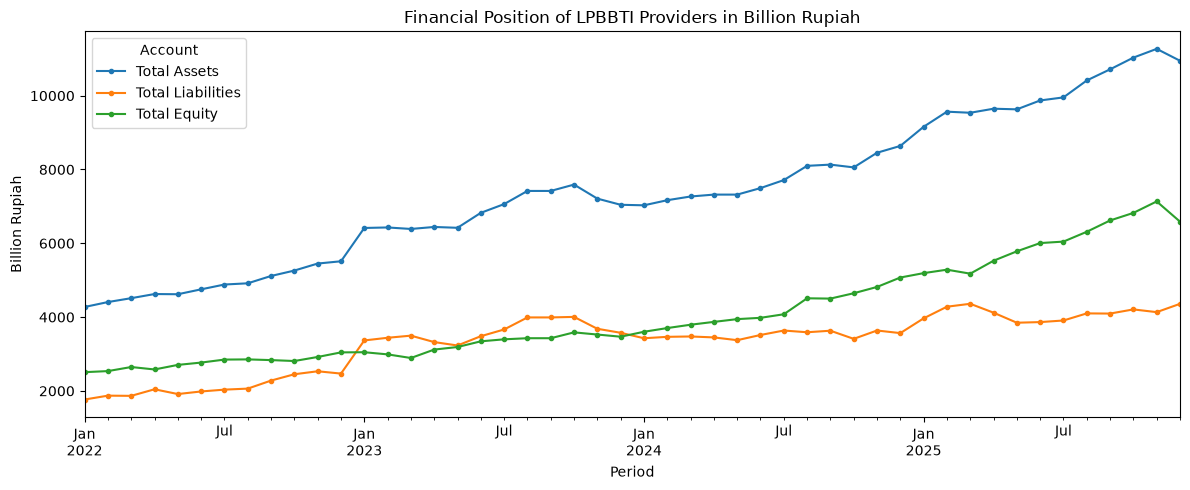

In [154]:
df_total_wide = df_total_main.pivot(index='Period', columns='Account', values='Billion')

df_total_wide[total_names].plot(figsize=(12, 5), marker='.')
plt.title('Financial Position of LPBBTI Providers in Billion Rupiah')
plt.xlabel('Period')
plt.ylabel('Billion Rupiah')
plt.legend(title='Account')
plt.tight_layout()
plt.savefig(FIGURE_DIR/'overall_financial_position.png')
plt.show()

In [155]:
first_last = df_total_wide[total_names].iloc[[0, -1]]
year_end_totals = df_total_wide[df_total_wide.index.month == 12].copy()
year_end_totals.index = year_end_totals.index.year
year_end_totals.index.name = 'Year'

print('> First and last month')
display(first_last)

print('\n> Last month / first month (x)')
display((first_last.iloc[1] / first_last.iloc[0]).round(2))

print('\n> Year-end balances')
display(year_end_totals[total_names])

print('\n> Change from the previous year-end')
display(year_end_totals[total_names].diff())

print('\n> Relative change % from the previous year-end')
display(year_end_totals[total_names].pct_change() * 100)

for total in total_names:
  monthly = pd.DataFrame({'Change': df_total_wide[total].diff(), 'Relative Change %': df_total_wide[total].pct_change() * 100}).dropna()

  print(f'\n{total}: 3 largest monthly falls, then 3 largest monthly rises')
  display(pd.concat([monthly.nsmallest(3, 'Relative Change %'), monthly.nlargest(3, 'Relative Change %')]))

> First and last month


Account,Total Assets,Total Liabilities,Total Equity
Period,,,
2022-01,4274.003746,1766.450423,2507.553323
2025-12,10946.260316,4359.349828,6586.910489



> Last month / first month (x)


Account
Total Assets         2.56
Total Liabilities    2.47
Total Equity         2.63
dtype: float64


> Year-end balances


...

,Change,Relative Change %
Period,,
2023-11,-380.614275,-5.014038
2025-12,-322.321521,-2.860356
2023-12,-166.958560,-2.315538
2023-01,902.577414,16.373050
2023-06,405.737655,6.320239
2025-01,518.942783,6.007424



Total Liabilities: 3 largest monthly falls, then 3 largest monthly rises


,Change,Relative Change %
Period,,
2023-11,-321.961985,-8.038738
2025-05,-272.160225,-6.606503
2022-05,-129.101962,-6.316756
2023-01,898.398043,36.387273
2025-01,400.015957,11.217797
2022-09,217.847037,10.565485



Total Equity: 3 largest monthly falls, then 3 largest monthly rises


,Change,Relative Change %
Period,,
2025-12,-547.416267,-7.672991
2023-03,-98.223115,-3.285494
2022-04,-66.121033,-2.498015
2024-08,432.848080,10.618060
2023-04,228.315459,7.896428
2025-04,350.363172,6.767968


 #### 11.3.2. Liabilities & Equity Share to Total Assets

Top 7 largest Liabilities % of Assets and smallest Equity % of Assets


Account,Total Assets,Total Liabilities,Total Equity,Liabilities % of Assets,Equity % of Assets
Period,,,,,
2023-03,6388.454854,3497.078388,2891.376465,54.740598,45.259402
2023-08,7418.582728,3990.884753,3427.697975,53.795784,46.204216
2023-09,7418.582728,3990.884753,3427.697975,53.795784,46.204216
2023-02,6429.029269,3439.429688,2989.599580,53.498429,46.501571
2023-10,7590.973012,4005.130931,3585.842081,52.761760,47.238240
2023-01,6415.156953,3367.387814,3047.769139,52.491121,47.508879
2023-07,7061.910539,3664.222095,3397.688444,51.887121,48.112879


Top 7 smallest Liabilities % of Assets and largest Equity % of Assets


Account,Total Assets,Total Liabilities,Total Equity,Liabilities % of Assets,Equity % of Assets
Period,,,,,
2025-11,11268.581837,4134.255082,7134.326755,36.688335,63.311665
2025-10,11031.569905,4208.090117,6823.479788,38.145886,61.854114
2025-09,10713.935299,4095.446712,6618.488587,38.225419,61.774581
2025-06,9870.501219,3864.566612,6005.934607,39.152689,60.847311
2025-07,9953.659647,3907.886004,6045.773643,39.260796,60.739204
2025-08,10412.410596,4100.214744,6312.195852,39.378151,60.621849
2025-12,10946.260316,4359.349828,6586.910489,39.825015,60.174985


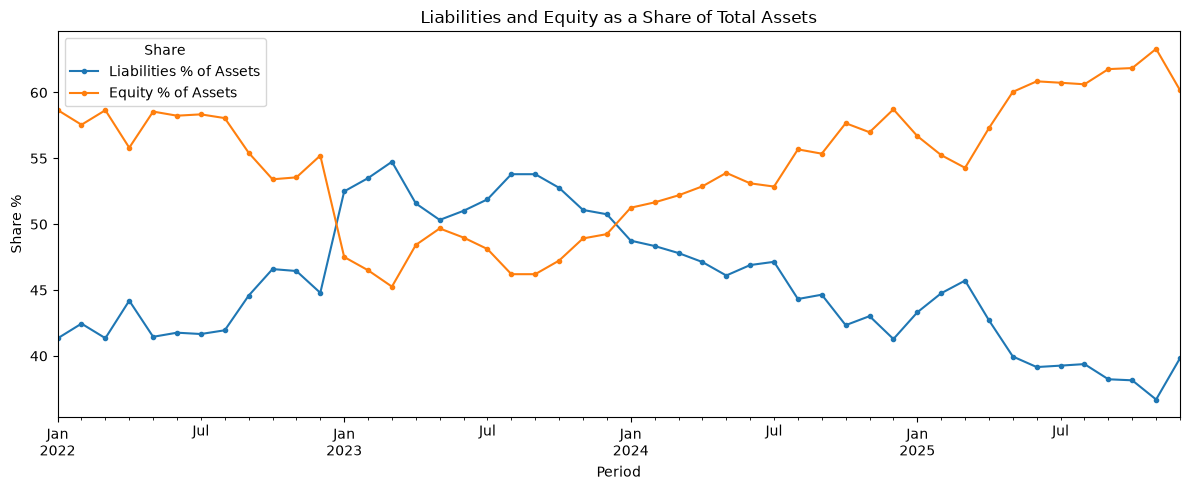

In [156]:
df_ratios = df_total_wide[total_names].copy()
df_ratios['Liabilities % of Assets'] = df_ratios['Total Liabilities'] / df_ratios['Total Assets'] * 100
df_ratios['Equity % of Assets'] = df_ratios['Total Equity'] / df_ratios['Total Assets'] * 100

print('Top 7 largest Liabilities % of Assets and smallest Equity % of Assets')
display(df_ratios.nlargest(7, 'Liabilities % of Assets'))

print('Top 7 smallest Liabilities % of Assets and largest Equity % of Assets')
display(df_ratios.nsmallest(7, 'Liabilities % of Assets'))

df_ratios[['Liabilities % of Assets', 'Equity % of Assets']].plot(figsize=(12, 5), marker='.')
plt.title('Liabilities and Equity as a Share of Total Assets')
plt.xlabel('Period')
plt.ylabel('Share %')
plt.legend(title='Share')
plt.tight_layout()
plt.savefig(FIGURE_DIR/'liabilities_equities_proportions.png')
plt.show()

#### 11.3.3. Share of Subtotals in Total Assets & Total Liabilities

Top 7 largest Current Assets % of Assets and smallest Fixed Assets % of Assets


,Current Assets % of Assets,Fixed Assets % of Assets
Period,,
2024-11,85.712991,14.287009
2024-10,85.322030,14.677970
2024-08,83.725220,16.274780
2024-09,83.594936,16.405064
2024-07,83.096329,16.903671
2024-12,82.277777,17.722223
2025-12,81.107389,18.892611


Top 7 smallest Current Assets % of Assets and largest Fixed Assets % of Assets


,Current Assets % of Assets,Fixed Assets % of Assets
Period,,
2022-01,70.155420,29.844580
2023-04,70.534435,29.465565
2023-01,70.766425,29.233575
2023-03,70.778504,29.221496
2022-02,70.889847,29.110153
2023-02,70.930335,29.069665
2023-05,71.304864,28.695136


Current Assets % of Assets average: 76.19821676457109, Fixed Assets % of Assets average: 23.801783235428914

Top 7 largest Current Liabilities % of Liabilities and smallest Long-Term Liabilities % of Liabilities


,Current Liabilities % of Liabilities,Long-Term Liabilities % of Liabilities
Period,,
2023-10,93.065988,6.934012
2023-11,92.868688,7.131312
2023-08,92.351149,7.648851
2023-09,92.351149,7.648851
2024-06,92.114326,7.885674
2023-12,91.947458,8.052542
2024-03,91.855020,8.144980


Top 7 smallest Current Liabilities % of Liabilities and largest Long-Term Liabilities % of Liabilities


,Current Liabilities % of Liabilities,Long-Term Liabilities % of Liabilities
Period,,
2022-01,82.189590,17.810410
2022-05,82.449805,17.550195
2022-02,82.912207,17.087793
2022-06,83.180107,16.819893
2022-04,84.065981,15.934019
2022-03,84.969154,15.030846
2022-07,86.381015,13.618985


Current Liabilitites % of Liabilities average: 88.78925044893371, Long-Term Liabilities % of Liabilities average: 11.210749551066286



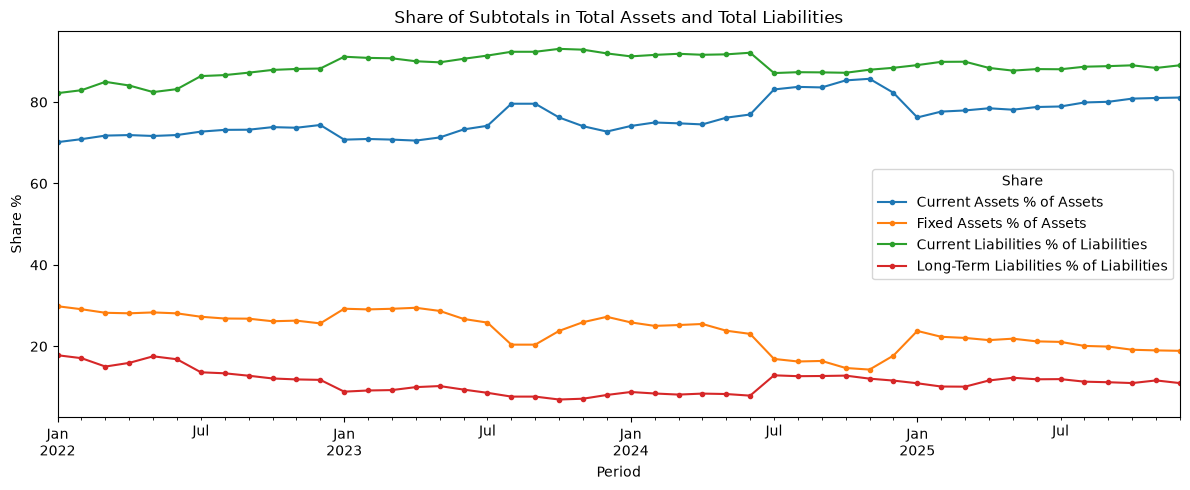

In [157]:
df_composition = pd.DataFrame({'Current Assets % of Assets': df_total_wide['Total Current Assets'] / df_total_wide['Total Assets'] * 100,
                               'Fixed Assets % of Assets': df_total_wide['Total Fixed Assets'] / df_total_wide['Total Assets'] * 100,
                               'Current Liabilities % of Liabilities': df_total_wide['Total Current Liabilities'] / df_total_wide['Total Liabilities'] * 100,
                               'Long-Term Liabilities % of Liabilities': df_total_wide['Total Long-Term Liabilities'] / df_total_wide['Total Liabilities'] * 100})

print('Top 7 largest Current Assets % of Assets and smallest Fixed Assets % of Assets')
display(df_composition[['Current Assets % of Assets', 'Fixed Assets % of Assets']].nlargest(7, 'Current Assets % of Assets'))

print('Top 7 smallest Current Assets % of Assets and largest Fixed Assets % of Assets')
display(df_composition[['Current Assets % of Assets', 'Fixed Assets % of Assets']].nsmallest(7, 'Current Assets % of Assets'))

current_assets_average = df_composition['Current Assets % of Assets'].mean()
print(f'Current Assets % of Assets average: {current_assets_average}, Fixed Assets % of Assets average: {100 - current_assets_average}\n')

print('Top 7 largest Current Liabilities % of Liabilities and smallest Long-Term Liabilities % of Liabilities')
display(df_composition[['Current Liabilities % of Liabilities', 'Long-Term Liabilities % of Liabilities']].nlargest(7, 'Current Liabilities % of Liabilities'))

print('Top 7 smallest Current Liabilities % of Liabilities and largest Long-Term Liabilities % of Liabilities')
display(df_composition[['Current Liabilities % of Liabilities', 'Long-Term Liabilities % of Liabilities']].nsmallest(7, 'Current Liabilities % of Liabilities'))

current_liabilities_average = df_composition['Current Liabilities % of Liabilities'].mean()
print(f'Current Liabilitites % of Liabilities average: {current_liabilities_average}, Long-Term Liabilities % of Liabilities average: {100 - current_liabilities_average}\n')

df_composition.plot(figsize=(12, 5), marker='.')
plt.title('Share of Subtotals in Total Assets and Total Liabilities')
plt.xlabel('Period')
plt.ylabel('Share %')
plt.legend(title='Share')
plt.tight_layout()
plt.savefig(FIGURE_DIR/'assets_liabilities_compositions.png')
plt.show()

### 11.4. RQ 2: Which accounts changed the most within comparable reporting periods, and how did those changes contribute to the related subtotal?

#### 11.4.1. Account Changes, Year-End to Year-End

In [158]:
year_end_accounts = df_long_main[df_long_main['Period'].dt.month == 12].pivot(index='Account', columns='Year', values='Billion')
year_end_accounts

Year,2022,2023,2024,2025
Account,,,,
Account Payable - Third Party,432.940428,579.887808,458.017384,539.011078
Accounts Receivables - Affiliated Party,NaN,NaN,51.080779,34.063456
Accounts Receivables - Third Party,NaN,NaN,1330.094913,2005.668696
Accrued Expenses,601.410109,1327.004409,818.099310,1565.222024
Accumulated Amortization,-216.980770,-404.448881,-551.479491,-788.029387
Accumulated Depreciation,-242.502306,-320.116247,-366.666555,-439.039835
Additional Paid-Up Capital,1382.776341,1232.364097,1060.024848,1141.397720
Allowance for Impairment Losses,NaN,NaN,-406.178724,-678.858431
"Building, Land and Equipment",470.672404,565.580900,592.885368,690.102284


In [159]:
comparison_periods = [(2022, 2023), (2023, 2024), (2024, 2025)]  # 2023-2024 crosses the reporting change and is exploratory

def account_changes(start_year, end_year):
  changes = year_end_accounts[[start_year, end_year]].dropna()
  changes.columns = ['Start Balance', 'End Balance']
  changes['Change'] = changes['End Balance'] - changes['Start Balance']
  changes['Abs Change'] = changes['Change'].abs()
  changes['Relative Change %'] = changes['Change'] / changes['Start Balance'].abs().replace(0, np.nan) * 100
  return changes.reset_index()

for start_year, end_year in comparison_periods:
  changes = account_changes(start_year, end_year)

  print(f'{start_year}-{end_year}: Top 7 largest nominal changes')
  display(changes.nlargest(7, 'Abs Change').reset_index(drop=True))

  print(f'\n{start_year}-{end_year}: Top 7 largest relative increases')
  display(changes.nlargest(7, 'Relative Change %').reset_index(drop=True))

  print(f'\n{start_year}-{end_year}: Top 7 largest relative decreases')
  display(changes.nsmallest(7, 'Relative Change %').reset_index(drop=True))
  print('')

2022-2023: Top 7 largest nominal changes


,Account,Start Balance,End Balance,Change,Abs Change,Relative Change %
0,Cash and Cash Equivalents,2044.667565,3107.076414,1062.408849,1062.408849,51.959980
1,Accrued Expenses,601.410109,1327.004409,725.594300,725.594300,120.648837
2,Intangible Assets,514.118710,1070.219624,556.100915,556.100915,108.165858
3,Profit (Loss) for the Period,-40.268982,323.410434,363.679416,363.679416,903.125437
4,Paid-Up Capital,3641.755764,3995.969830,354.214066,354.214066,9.726464
5,Other Current Receivables - Third Party,1038.704155,805.915291,-232.788864,232.788864,-22.411469
6,Accumulated Amortization,-216.980770,-404.448881,-187.468110,187.468110,-86.398491



2022-2023: Top 7 largest relative increases


,Account,Start Balance,End Balance,Change,Abs Change,Relative Change %
0,Profit (Loss) for the Period,-40.268982,323.410434,363.679416,363.679416,903.125437
1,Deferred Tax Liabilities,0.044805,0.175902,0.131097,0.131097,292.594543
2,Non-Controlling Interests,-4.399812,4.074889,8.474701,8.474701,192.615057
3,Other Fixed Assets,109.689687,246.634619,136.944933,136.944933,124.847592
4,Short-Term Investments,44.060413,98.550519,54.490105,54.490105,123.671344
5,Accrued Expenses,601.410109,1327.004409,725.594300,725.594300,120.648837
6,Intangible Assets,514.118710,1070.219624,556.100915,556.100915,108.165858



2022-2023: Top 7 largest relative decreases


...

,Account,Start Balance,End Balance,Change,Abs Change,Relative Change %
0,Cash and Cash Equivalents,3909.517228,5089.675933,1180.158704,1180.158704,30.186814
1,Retained Earnings,-1757.521146,-862.105374,895.415773,895.415773,50.947653
2,Other Current Receivables - Affiliated Party,199.377414,962.433156,763.055741,763.055741,382.719248
3,Accrued Expenses,818.099310,1565.222024,747.122715,747.122715,91.324208
4,Short-Term Investments,745.103523,26.943797,-718.159726,718.159726,-96.383885
5,Accounts Receivables - Third Party,1330.094913,2005.668696,675.573782,675.573782,50.791397
6,Long-Term Investments,26.200000,651.866390,625.666390,625.666390,2388.039655



2024-2025: Top 7 largest relative increases


,Account,Start Balance,End Balance,Change,Abs Change,Relative Change %
0,Long-Term Investments,26.200000,651.866390,625.666390,625.666390,2388.039655
1,Other Long-Term Liabilities - Third Party,2.453522,16.454496,14.000974,14.000974,570.648014
2,Other Current Receivables - Affiliated Party,199.377414,962.433156,763.055741,763.055741,382.719248
3,Prepaid Taxes,328.148945,698.186816,370.037871,370.037871,112.765217
4,Accrued Expenses,818.099310,1565.222024,747.122715,747.122715,91.324208
5,Lease Liabilities,53.219291,84.156580,30.937288,30.937288,58.131718
6,Retained Earnings,-1757.521146,-862.105374,895.415773,895.415773,50.947653



2024-2025: Top 7 largest relative decreases


,Account,Start Balance,End Balance,Change,Abs Change,Relative Change %
0,Non-Controlling Interests,0.537451,0.000000,-0.537451,0.537451,-100.000000
1,Short-Term Investments,745.103523,26.943797,-718.159726,718.159726,-96.383885
2,Other Long-Term Receivables - Affiliated Party,3.495901,0.405038,-3.090863,3.090863,-88.413924
3,Other Current Assets,442.374123,111.160252,-331.213871,331.213871,-74.871891
4,Allowance for Impairment Losses,-406.178724,-678.858431,-272.679707,272.679707,-67.132937
5,Other Equity,-283.097700,-465.381691,-182.283991,182.283991,-64.389075
6,Other Current Liabilities - Third Party,458.606546,239.763667,-218.842879,218.842879,-47.719092


 #### 11.4.2. Contribution to Subtotal Changes

In [160]:
def subtotal_contributions(subtotal, start_year, end_year):
  names = accounts_22_23[subtotal] if end_year <= 2023 else accounts_24_25[subtotal]
  subtotal_change = year_end_totals.loc[end_year, subtotal] - year_end_totals.loc[start_year, subtotal]

  table = year_end_accounts.reindex(names)[[start_year, end_year]]
  table.columns = ['Start Balance', 'End Balance']
  table['Change'] = table['End Balance'] - table['Start Balance']
  table = table.sort_values('Change', key=abs, ascending=False, kind='stable')

  unreconciled = subtotal_change - table['Change'].sum()  # accounts with no start balance stay here
  table.loc['Unreconciled Difference', 'Change'] = 0.0 if np.isclose(unreconciled, 0, atol=1e-6) else unreconciled
  table['Share % of Subtotal Change'] = table['Change'] / subtotal_change * 100
  return table, subtotal_change

for subtotal in subtotal_names:
  for start_year, end_year in comparison_periods:
    table, subtotal_change = subtotal_contributions(subtotal, start_year, end_year)

    print(f'{subtotal}: {start_year}-{end_year} (subtotal change {subtotal_change:.1f})')
    display(table.reset_index())
    print('')

Total Current Assets: 2022-2023 (subtotal change 1024.7)


,Account,Start Balance,End Balance,Change,Share % of Subtotal Change
0,Cash and Cash Equivalents,2044.667565,3107.076414,1062.408849,103.679457
1,Other Current Receivables - Third Party,1038.704155,805.915291,-232.788864,-22.717641
2,Prepaid Taxes,138.532508,207.288451,68.755943,6.709826
3,Short-Term Investments,44.060413,98.550519,54.490105,5.317637
4,Other Current Receivables - Affiliated Party,460.690830,506.007188,45.316357,4.422380
5,Other Current Assets,135.465742,151.676014,16.210273,1.581945
6,Prepaid Expenses,237.478799,247.791398,10.312598,1.006397
7,Unreconciled Difference,NaN,NaN,0.000000,0.000000



Total Current Assets: 2023-2024 (subtotal change 1983.1)


,Account,Start Balance,End Balance,Change,Share % of Subtotal Change
0,Cash and Cash Equivalents,3107.076414,3909.517228,802.440814,40.463067
1,Short-Term Investments,98.550519,745.103523,646.553005,32.602426
2,Other Current Receivables - Third Party,805.915291,216.725404,-589.189887,-29.709892
3,Other Current Receivables - Affiliated Party,506.007188,199.377414,-306.629773,-15.461802
4,Other Current Assets,151.676014,442.374123,290.698108,14.658448
5,Prepaid Taxes,207.288451,328.148945,120.860494,6.094389
6,Prepaid Expenses,247.791398,255.429825,7.638427,0.385168
7,Accounts Receivables - Affiliated Party,NaN,51.080779,NaN,NaN
8,Accounts Receivables - Third Party,NaN,1330.094913,NaN,NaN
9,Allowance for Impairment Losses,NaN,-406.178724,NaN,NaN



Total Current Assets: 2024-2025 (subtotal change 1770.8)


...

,Account,Start Balance,End Balance,Change,Share % of Subtotal Change
0,Profit (Loss) for the Period,-40.268982,323.410434,363.679416,85.576392
1,Paid-Up Capital,3641.755764,3995.969830,354.214066,83.349127
2,Retained Earnings,-1936.273542,-2087.253144,-150.979602,-35.526590
3,Additional Paid-Up Capital,1382.776341,1232.364097,-150.412243,-35.393087
4,Non-Controlling Interests,-4.399812,4.074889,8.474701,1.994158
5,Unreconciled Difference,NaN,NaN,0.000000,0.000000



Total Equity: 2023-2024 (subtotal change 1603.9)


,Account,Start Balance,End Balance,Change,Share % of Subtotal Change
0,Profit (Loss) for the Period,323.410434,1651.233135,1327.822701,82.787770
1,Retained Earnings,-2087.253144,-1757.521146,329.731998,20.558299
2,Additional Paid-Up Capital,1232.364097,1060.024848,-172.339249,-10.745096
3,Paid-Up Capital,3995.969830,3978.232554,-17.737276,-1.105893
4,Non-Controlling Interests,4.074889,0.537451,-3.537438,-0.220554
5,Capital Deposit Down Payment,NaN,423.044479,NaN,NaN
6,Other Equity,NaN,-283.097700,NaN,NaN
7,Unreconciled Difference,NaN,NaN,139.946779,8.725473



Total Equity: 2024-2025 (subtotal change 1514.5)


,Account,Start Balance,End Balance,Change,Share % of Subtotal Change
0,Retained Earnings,-1757.521146,-862.105374,895.415773,59.124548
1,Profit (Loss) for the Period,1651.233135,2269.618634,618.385498,40.832163
2,Paid-Up Capital,3978.232554,4176.748809,198.516255,13.108082
3,Other Equity,-283.097700,-465.381691,-182.283991,-12.036262
4,Capital Deposit Down Payment,423.044479,326.632390,-96.412089,-6.366117
5,Additional Paid-Up Capital,1060.024848,1141.397720,81.372872,5.373073
6,Non-Controlling Interests,0.537451,0.000000,-0.537451,-0.035488
7,Unreconciled Difference,NaN,NaN,0.000000,0.000000


### 11.5. RQ 3: Which accounts show sustained or unusual monthly movements, and how can we tell a lasting change from a temporary one?

#### 11.5.1. Monthly Movement Table

In [161]:
z_threshold = 3.5  # common cutoff for robust (modified) z-scores, Iglewicz and Hoaglin (1993)
horizon = 3  # months after a flagged change

df_movements = df_long_main.rename(columns={'Billion': 'Balance'}).sort_values(['Account', 'Period'], ignore_index=True)
df_movements['Segment'] = np.where(df_movements['Year'] <= 2023, '2022-2023', '2024-2025')

def by_series(column):
  # one series per account and segment, so no change crosses the 2023/2024 boundary
  return df_movements.groupby(['Segment', 'Account'])[column]

df_movements['Previous Balance'] = by_series('Balance').shift(1)
df_movements['Change'] = df_movements['Balance'] - df_movements['Previous Balance']
df_movements['Abs Change'] = df_movements['Change'].abs()
df_movements['Relative Change %'] = df_movements['Change'] / df_movements['Previous Balance'].abs().replace(0, np.nan) * 100

# Sustained: the third or later change in the same direction
df_movements['Direction'] = np.sign(df_movements['Change'])
df_movements['Sustained'] = (df_movements['Direction'].ne(0) & df_movements['Direction'].eq(by_series('Direction').shift(1))
                             & df_movements['Direction'].eq(by_series('Direction').shift(2)))

# Unusual (flagged): robust z-score of the change, from the median and MAD of the account in its segment
median = by_series('Change').transform('median')
mad = by_series('Change').transform(lambda change: (change - change.median()).abs().median())

df_movements['Median'] = median
df_movements['MAD'] = mad
df_movements['Robust Z-Score'] = 0.6745 * (df_movements['Change'] - median) / mad.where(mad > 0)
df_movements['Flagged'] = df_movements['Robust Z-Score'].abs() > z_threshold

# Lasting or temporary: 3 months later, is the balance closer to the new balance or to the old one?
df_movements['Later Balance'] = by_series('Balance').shift(-horizon)
distance_to_new = (df_movements['Later Balance'] - df_movements['Balance']).abs()
distance_to_old = (df_movements['Later Balance'] - df_movements['Previous Balance']).abs()
can_assess = df_movements['Later Balance'].notna() & df_movements['Change'].notna() & df_movements['Change'].ne(0)
df_movements['Result'] = np.select([~can_assess, distance_to_new <= distance_to_old], ['Not assessed', 'Lasting'], default='Temporary')

df_flagged = df_movements[df_movements['Flagged']]
df_sustained = df_movements[df_movements['Sustained']]

#### 11.5.2. Sustained & Unusual Movements

In [162]:
scored = df_movements['Robust Z-Score'].notna().sum()
can_be_sustained = (df_movements['Direction'].notna() & by_series('Direction').shift(1).notna() & by_series('Direction').shift(2).notna())

print(f'Scored account-months: {scored}')
print(f'Can be sustained: {can_be_sustained.sum()}')
print(f'Flagged account-months: {len(df_flagged)} ({len(df_flagged) / scored:.1%} of scored) in {df_flagged["Account"].nunique()} of {df_movements["Account"].nunique()} accounts')
print(f'Sustained account-months: {len(df_sustained)} ({len(df_sustained) / can_be_sustained.sum():.1%} of can be sustained) in {df_sustained["Account"].nunique()} of {df_movements["Account"].nunique()} accounts')

print('\n Top 5 months with the most flagged accounts')
display(df_flagged['Period'].value_counts().head(5))

print(f'Account-segment series: {df_movements.groupby(["Segment", "Account"]).ngroups}')

print('\nSeries without a robust z-score (MAD = 0)')
not_scored = df_movements[df_movements['Change'].notna() & df_movements['Robust Z-Score'].isna()].groupby(['Segment', 'Account'])
display(pd.DataFrame({'Changes': not_scored.size(), 'Zero Changes': not_scored['Change'].apply(lambda change: change.eq(0).sum()),
                      'Largest Abs Change': not_scored['Abs Change'].max()}))

Scored account-months: 1522
Can be sustained: 1439
Flagged account-months: 166 (10.9% of scored) in 34 of 40 accounts
Sustained account-months: 447 (31.1% of can be sustained) in 38 of 40 accounts

 Top 5 months with the most flagged accounts


Period
2024-07    13
2023-11    10
2025-04     9
2022-12     7
2024-10     7
Freq: M, Name: count, dtype: int64

Account-segment series: 72

Series without a robust z-score (MAD = 0)


Changes  Zero Changes  \
Segment   Account                                                            
2024-2025 Deferred Tax Liabilities                        20            17   
          Financial Debt                                  20            15   
          Non-Controlling Interests                       23            15   
          Other Long-Term Receivables - Unallocated        1             0   

                                                     Largest Abs Change  
Segment   Account                                                        
2024-2025 Deferred Tax Liabilities                            38.718386  
          Financial Debt                                       9.127061  
          Non-Controlling Interests                            9.880198  
          Other Long-Term Receivables - Unallocated           21.651237

#### 11.5.3. Lasting or Temporary Changes

In [163]:
print(f'Flagged months by result ({horizon} months later)')
display(df_flagged['Result'].value_counts())

assessed = df_flagged[df_flagged['Result'] != 'Not assessed']
not_assessed = df_flagged[df_flagged['Result'] == 'Not assessed']
print(f'Assessed flagged months: {len(assessed)} of {len(df_flagged)}, lasting share of assessed: {(assessed["Result"] == "Lasting").mean():.1%}')
print(f'Not assessed: {not_assessed["Later Balance"].isna().sum()} with no balance {horizon} months later, {not_assessed["Change"].eq(0).sum()} with a change of 0')

print('\nNot assessed flagged months by period')
display(not_assessed['Period'].value_counts().sort_index())

print('\nLargest flagged changes by amount')
display(df_flagged.nlargest(8, 'Abs Change')[['Period', 'Account', 'Previous Balance', 'Balance', 'Later Balance', 'Change',
                                              'Robust Z-Score', 'Result']].reset_index(drop=True))

Flagged months by result (3 months later)


Result
Lasting         93
Temporary       47
Not assessed    26
Name: count, dtype: int64

Assessed flagged months: 140 of 166, lasting share of assessed: 66.4%
Not assessed: 25 with no balance 3 months later, 1 with a change of 0

Not assessed flagged months by period


Period
2023-09     1
2023-10     4
2023-11    10
2023-12     5
2025-10     1
2025-11     2
2025-12     3
Freq: M, Name: count, dtype: int64


Largest flagged changes by amount


,Period,Account,Previous Balance,Balance,Later Balance,Change,Robust Z-Score,Result
0,2025-01,Profit (Loss) for the Period,1651.233135,152.215254,562.295907,-1499.017882,-11.321461,Lasting
1,2025-01,Retained Earnings,-1757.521146,-269.288445,-190.436445,1488.232701,15.150891,Lasting
2,2025-04,Retained Earnings,-1013.112617,-190.436445,-782.493248,822.676171,8.497395,Temporary
3,2025-03,Retained Earnings,-255.296442,-1013.112617,-323.123724,-757.816175,-7.302615,Temporary
4,2024-07,Paid-Up Capital,4258.279150,3631.637799,3991.022554,-626.641351,-16.121941,Temporary
5,2025-01,Short-Term Investments,745.103523,125.083128,127.395066,-620.020395,-71.396322,Lasting
6,2025-01,Long-Term Investments,26.200000,645.972097,634.259599,619.772097,41.803628,Lasting
7,2024-07,Other Current Receivables - Third Party,833.592767,223.256935,290.303789,-610.335832,-8.109121,Lasting


#### 11.5.4. Review of Sustained Accounts

In [164]:
is_rising = df_sustained['Direction'] > 0
sustained_by_account = df_sustained.groupby('Account')

account_sustains = pd.DataFrame({'Sustained Months': sustained_by_account.size(),
                                 'Rising': is_rising.groupby(df_sustained['Account']).sum(),
                                 'Falling': (~is_rising).groupby(df_sustained['Account']).sum()})
account_sustains['Flagged Months'] = df_flagged.groupby('Account').size().reindex(account_sustains.index, fill_value=0)
account_sustains = account_sustains.sort_values('Sustained Months', ascending=False, kind='stable')

print('Accounts with the most sustained months')
display(account_sustains.head(5))

Accounts with the most sustained months


,Sustained Months,Rising,Falling,Flagged Months
Account,,,,
Accumulated Amortization,35,0,35,1
Accumulated Depreciation,27,0,27,2
"Building, Land and Equipment",24,23,1,1
Profit (Loss) for the Period,24,21,3,1
Intangible Assets,22,20,2,6


#### 11.5.5. Review of Flagged Accounts

In [165]:
flags_by_account = df_flagged.groupby('Account')
account_flags = pd.DataFrame({'Flagged Months': flags_by_account.size(), 'Largest Abs Change': flags_by_account['Abs Change'].max()})
account_flags = account_flags.sort_values(['Flagged Months', 'Largest Abs Change'], ascending=False)

print('Accounts with the most flagged months')
display(account_flags.head(5))

reviewed_accounts = account_flags.index[:5].tolist()
review_columns = ['Period', 'Account', 'Previous Balance', 'Balance', 'Later Balance', 'Change', 'Relative Change %', 'Robust Z-Score', 'Result']

print('\nFlagged months of the reviewed accounts')
display(df_flagged[df_flagged['Account'].isin(reviewed_accounts)].sort_values(['Account', 'Period'])[review_columns].reset_index(drop=True))

Accounts with the most flagged months


,Flagged Months,Largest Abs Change
Account,,
Long-Term Investments,14,619.772097
Other Long-Term Receivables - Affiliated Party,13,29.819703
Short-Term Investments,11,620.020395
Other Long-Term Receivables - Third Party,11,100.597821
Deferred Tax Liabilities,11,1.602108



Flagged months of the reviewed accounts


,Period,Account,Previous Balance,Balance,Later Balance,Change,Relative Change %,Robust Z-Score,Result
0,2022-04,Deferred Tax Liabilities,1.617926,1.630164,0.028955,0.012239,0.756444,5.493481,Temporary
1,2022-07,Deferred Tax Liabilities,1.631063,0.028955,0.046819,-1.602108,-98.224798,-719.124465,Lasting
2,2022-10,Deferred Tax Liabilities,0.028371,0.046819,0.044418,0.018448,65.026035,8.280734,Lasting
3,2022-11,Deferred Tax Liabilities,0.046819,0.081062,0.005788,0.034243,73.139223,15.370372,Temporary
4,2022-12,Deferred Tax Liabilities,0.081062,0.044805,0.029304,-0.036257,-44.727468,-16.274356,Lasting
5,2023-02,Deferred Tax Liabilities,0.044418,0.005788,0.059134,-0.038629,-86.968114,-17.339279,Temporary
6,2023-03,Deferred Tax Liabilities,0.005788,0.029304,0.068689,0.023515,406.240046,10.555066,Lasting
7,2023-05,Deferred Tax Liabilities,0.029304,0.059134,0.068689,0.029831,101.798667,13.389884,Lasting
8,2023-06,Deferred Tax Liabilities,0.059134,0.068689,0.068689,0.009554,16.156633,4.288485,Lasting
9,2023-10,Deferred Tax Liabilities,0.068689,0.134285,NaN,0.065597,95.498663,29.443832,Not assessed


In [166]:
# All unusual changes in the month with the most flagged accounts
peak_month = df_flagged['Period'].value_counts().idxmax()
peak_changes = df_flagged[df_flagged['Period'] == peak_month].sort_values('Abs Change', ascending=False)

print(f'Unusual changes in {peak_month}: {len(peak_changes)} accounts')
display(peak_changes['Result'].value_counts())
display(peak_changes[['Account', 'Previous Balance', 'Balance', 'Change', 'Abs Change', 'Result']].reset_index(drop=True))

Unusual changes in 2024-07: 13 accounts


Result
Lasting      9
Temporary    4
Name: count, dtype: int64

,Account,Previous Balance,Balance,Change,Abs Change,Result
0,Paid-Up Capital,4258.279150,3631.637799,-626.641351,626.641351,Temporary
1,Other Current Receivables - Third Party,833.592767,223.256935,-610.335832,610.335832,Lasting
2,Long-Term Investments,445.850979,26.246296,-419.604682,419.604682,Lasting
3,Short-Term Investments,253.137464,649.850840,396.713376,396.713376,Lasting
4,Other Current Liabilities - Affiliated Party,420.930805,790.760662,369.829857,369.829857,Temporary
5,Other Current Assets,243.541303,582.056794,338.515491,338.515491,Temporary
6,Accrued Expenses,1186.411810,906.227419,-280.184391,280.184391,Lasting
7,Account Payable - Third Party,686.465268,482.304080,-204.161188,204.161188,Lasting
8,Other Long-Term Liabilities - Affiliated Party,45.365588,205.204433,159.838845,159.838845,Lasting
9,Additional Paid-Up Capital,1201.669106,1062.071425,-139.597681,139.597681,Lasting


## 12. Findings and Limitations
Amounts are in billion Rupiah and come from the outputs above. Findings are descriptive: what changed and when, not why. 

Sections 12.1-12.3 answer the RQs, 12.4 covers the Non RQ analyses and 12.5 lists the limitations.

### 12.1. RQ 1: How did the overall financial position of LPBBTI providers change over time, by total assets, total liabilities, and total equity? (Section 11.3)

**Short answer:** All three totals grew about 2.5 times from Jan-22 to Dec-25. Total Liabilities grew the fastest in 2023, and Total Equity in 2024.

| Total | Jan-22 | Dec-25 | Growth | 2023 | 2024 | 2025 |
|---|---|---|---|---|---|---|
| Total Assets | 4,274.0 | 10,946.3 | 2.56x | +27.77% | +22.64% | +26.72% |
| Total Liabilities | 1,766.5 | 4,359.3 | 2.47x | +44.79% | -0.25% | +22.25% |
| Total Equity | 2,507.6 | 6,586.9 | 2.63x | +13.96% | +46.24% | +29.86% |

- **2023 had the biggest monthly jumps and drops (11.3.1).**

  | Month | Total Assets | Total Liabilities |
  |---|---|---|
  | Jan-23 (largest rise) | +902.6 | +898.4 |
  | Nov-23 (largest fall) | -380.6 | -322.0 |

  *Why it matters:* the biggest jumps and drops in Total Assets came mostly from liabilities.

- **Liabilities were the bigger part of Total Assets in 2023, equity in 2025 (11.3.2).** The 7 months with the highest liabilities share are all in 2023 (up to 54.74% in Mar-23). The 7 months with the highest equity share are all in 2025 (up to 63.31% in Nov-25).
  - *Why it matters:* after 2023, more of the assets were funded by equity and less by liabilities.

- **Most assets and liabilities are short-term (11.3.3).**

  | Share | Average | Highest |
  |---|---|---|
  | Current assets, % of Total Assets | 76.20% | 85.71% (Nov-24) |
  | Current liabilities, % of Total Liabilities | 88.79% | 93.07% (Oct-23) |

  *Why it matters:* this fits RQ 2, where the biggest changes come from short-term accounts such as Cash and Accrued Expenses.

### 12.2. RQ 2: Which accounts changed the most within comparable reporting periods, and how did those changes contribute to the related subtotal? (Section 11.4)

**Short answer:** Cash and Cash Equivalents changed the most in both comparable periods (2022-2023 and 2024-2025). It also made up most of the change in Total Current Assets (103.68% and 66.65%). A share above 100% means other accounts moved the other way. Accrued Expenses is the only other account in the top 7 by amount in every period.

- **Biggest changes by amount (11.4.1).**

  | Period | 1st | 2nd | 3rd |
  |---|---|---|---|
  | 2022-2023 | Cash and Cash Equivalents +1,062.4 | Accrued Expenses +725.6 | Intangible Assets +556.1 |
  | 2023-2024 (exploratory) | Profit (Loss) for the Period +1,327.8 | Cash and Cash Equivalents +802.4 | Short-Term Investments +646.6 |
  | 2024-2025 | Cash and Cash Equivalents +1,180.2 | Retained Earnings +895.4 | Other Current Receivables - Affiliated Party +763.1 |

  *Why it matters:* ranking by amount shows what really moved. Ranking by percentage puts small accounts on top, such as Other Long-Term Receivables - Third Party, up 11,344.54% from only 1.16.

- **What made Total Equity grow changed (11.4.2).**

  | Period | Biggest part of the Total Equity change |
  |---|---|
  | 2022-2023 | Profit (Loss) for the Period, 85.58% |
  | 2023-2024 | Profit (Loss) for the Period, 82.79% |
  | 2024-2025 | Retained Earnings, 59.12% |

  *Why it matters:* Retained Earnings is still negative, meaning past losses, but it went from -1,757.5 to -862.1 in 2024-2025. Equity grew mostly because those past losses got smaller.

- **Some changes cancel each other out (11.4.2).** In 2024-2025, Total Current Assets rose 1,770.8.

  | Account | Change | Share of the Total Current Assets change |
  |---|---|---|
  | Cash and Cash Equivalents | +1,180.2 | 66.65% |
  | Other Current Receivables - Affiliated Party | +763.1 | 43.09% |
  | Short-Term Investments | -718.2 | -40.56% |

  *Why it matters:* the rise of 1,770.8 looks simple, but it combines two big increases and one big decrease. Looking only at the subtotal would miss this.

### 12.3. RQ 3: Which accounts show sustained or unusual monthly movements, and how can we tell a lasting change from a temporary one? (Section 11.5)

**Short answer:** Each account's monthly change goes through three simple checks:
- **Unusual:** the change is much bigger than that account's usual change (robust z-score above 3.5).
- **Sustained:** the account moves in the same direction three or more times in a row.
- **Lasting or temporary:** 3 months later, the balance is either closer to the new level (lasting) or back near the old one (temporary).

| Check | Result |
|---|---|
| Unusual | 166 of the 1,522 account-months that could be checked (10.91%), in 34 of 40 accounts |
| Sustained | 447 of the 1,439 account-months that could be checked (31.06%), in 38 of 40 accounts |
| Lasting or temporary | Of the 140 unusual months that could be checked 3 months later, 93 lasted (66.43%) and 47 were temporary |

- **Jul-24 had the most unusual changes, in 13 accounts (11.5.2, 11.5.5).** 9 of them lasted and 4 were temporary. They cover assets, liabilities and equity. The five biggest:

  | Account | Jun-24 | Jul-24 | Change | Abs Change | Result |
  |---|---|---|---|---|---|
  | Paid-Up Capital | 4,258.3 | 3,631.6 | -626.6 | 626.6 | Temporary |
  | Other Current Receivables - Third Party | 833.6 | 223.3 | -610.3 | 610.3 | Lasting |
  | Long-Term Investments | 445.9 | 26.2 | -419.6 | 419.6 | Lasting |
  | Short-Term Investments | 253.1 | 649.9 | +396.7 | 396.7 | Lasting |
  | Other Current Liabilities - Affiliated Party | 420.9 | 790.8 | +369.8 | 369.8 | Temporary |

  *Why it matters:* Jul-24 is the first month of the new report format. It is also the first month with values for seven new accounts, and it has reporting gaps (Sections 8.1.4 and 8.1.5). So part of these changes may come from the format change.

- **The biggest unusual changes (11.5.3).**

  | Month | Account | Change | Result |
  |---|---|---|---|
  | Jan-25 | Profit (Loss) for the Period | -1,499.0 | Lasting |
  | Jan-25 | Retained Earnings | +1,488.2 | Lasting |
  | Mar-25 | Retained Earnings | -757.8 | Temporary |
  | Apr-25 | Retained Earnings | +822.7 | Temporary |

  *Why it matters:* the Jan-25 pair almost cancel each other out. This fits the usual step where last year's profit is moved into retained earnings. So an unusual change is a reason to check, not proof of a mistake.

- **Which accounts move unusually or steadily (11.5.4, 11.5.5).**

  | Most unusual months | Months | Biggest change |
  |---|---|---|
  | Long-Term Investments | 14 | 619.8 |
  | Other Long-Term Receivables - Affiliated Party | 13 | 29.8 |
  | Short-Term Investments | 11 | 620.0 |
  | Other Long-Term Receivables - Third Party | 11 | 100.6 |
  | Deferred Tax Liabilities | 11 | 1.6 |

  | Most sustained months | Months | Rising | Falling | Unusual months |
  |---|---|---|---|---|
  | Accumulated Amortization | 35 | 0 | 35 | 1 |
  | Accumulated Depreciation | 27 | 0 | 27 | 2 |
  | Building, Land and Equipment | 24 | 23 | 1 | 1 |
  | Profit (Loss) for the Period | 24 | 21 | 3 | 1 |
  | Intangible Assets | 22 | 20 | 2 | 6 |

  *Why it matters:* many unusual months do not mean big amounts. Deferred Tax Liabilities has 11 unusual months, but its biggest change is only 1.6. The steadiest accounts move almost always in one direction and have only 11 unusual months between them.

### 12.4. Non RQ: Supporting Analyses (Sections 11.1 and 11.2)

**Short answer:** The list of accounts changes in Jul-24, and Paid-Up Capital and Cash and Cash Equivalents are the largest accounts.

- **Account coverage (11.1).**

  | Accounts | Count | Has values |
  |---|---|---|
  | In every year | 32 | 2022 to 2025 |
  | New in the 2024 report | 7 | from Jul-24 |
  | Residual from Section 9.1 | 1 | Jul-Aug 2024 |

  *Why it matters:* comparisons across Jul-24 do not cover the same accounts, which is one reason RQ 2 and RQ 3 look at 2022-2023 and 2024-2025 separately.

- **Largest accounts (11.2).**

  | Account | Average balance | CV |
  |---|---|---|
  | Paid-Up Capital | 3,888.0 | 8.36% |
  | Cash and Cash Equivalents | 3,134.9 | 35.95% |

  *Why it matters:* Cash's higher CV is partly because it grew from 1,354.3 to 5,089.7, which fits RQ 2, where Cash changed the most.


### 12.5. Limitations

- **The report format changed in 2024.** The 2024-2025 period starts in Jan-24, but the new accounts only start in Jul-24, so the Jul-24 jump counts as part of that period's normal range. The Sep-24 Financial Debt (3,169.1 set to 0) and the Jul-Aug 2024 unallocated receivables were fixed for the analysis (Section 9.1).
- **RQ 3 uses simple rules.** Each account is compared only with its own history, so a smaller change can look more unusual than a bigger one. Long-Term Investments -300.0 in Aug-23 scores -1,569.3, while -419.6 in Jul-24 scores -28.3 (11.5.5). 26 of 166 unusual months cannot be checked 3 months later (11.5.3), and four accounts in 2024-2025 get no score because their balance barely moves (11.5.2).
- **Some data gaps remain.** Sep-23 repeats Aug-23 for 36 accounts (Section 7.3), so the Oct-23 change covers two months. Financial Debt and Deferred Tax Liabilities are blank in Jul-Aug 2024 (Section 8.1.5). Year-end comparisons in RQ 2 miss changes within the year, such as the Jul-24 to Jan-25 investment shift.